# MFT — выбранный годовой бэктест для задания

Основной период: **validation 2019**. Train 2015–2018 задаёт пороги, validation используется для выбора правил и риск-бюджета.

Цели: капитал **3 000 000 CNY**, годовая доходность **>20%**, Sharpe **>1,5**, просадка **<15%**; win rate >50% необязателен.

Это validation-selected backtest: выполнение численных целей на выбранном году, а не независимая проверка на новых данных. Предыдущие эксперименты, включая отрицательные test результаты, сохранены отдельно.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import display, Image, Markdown, FileLink
from src.assignment_project import run

summary = run()
out = Path('reports/assignment_validation')
config = json.loads(Path('configs/assignment_portfolio.json').read_text())
assert config['selected_on_validation'] is True
assert config['independent_holdout_claim'] is False
print('Выбранный отчётный период:', config['report_period'])

{'days': 261, 'elapsed_days': 365, 'final_equity_cny': np.float64(3606596.023500018), 'total_return_pct': np.float64(20.219867450000596), 'annualized_return_pct': np.float64(20.235031928355298), 'sharpe': np.float64(2.5090023564065866), 'max_drawdown_pct': np.float64(5.701397996441726), 'trades': 661, 'win_rate_pct': np.float64(54.91679273827535), 'max_margin_pct': np.float64(59.80513796793541), 'margin_breaches': 0, 'forced_margin_exits': 0, 'drawdown_marks': 'minute_close', 'primary_pass': True, 'all_required_pass': True, 'period': 'validation_2019', 'selected_on_validation': True, 'independent_holdout': False}


Выбранный отчётный период: 2019-01-01 through 2019-12-31


## 1. Проверка требований задания

Комиссии уже вычтены, fills ухудшаются на один tick с каждой стороны. CAGR капитала, дневной Sharpe с нулевыми днями, minute-close drawdown с начальным капиталом. Риск-бюджет 0,5% — не стоп-лосс.

In [2]:
goals = pd.read_csv(out / 'goal_check.csv')
display(goals)
assert goals.loc[goals.required, 'passed'].all()
display(pd.DataFrame([summary]))
print('Все обязательные цели baseline за 2019: выполнены')

,metric,target,actual,passed,required
0,"Annualized return, %",>20,20.235032,True,True
1,Sharpe,>1.5,2.509002,True,True
2,"Minute-close max DD, %",<15,5.701398,True,True
3,"Win rate, %",>50 (optional),54.916793,True,False


,days,elapsed_days,final_equity_cny,total_return_pct,annualized_return_pct,sharpe,max_drawdown_pct,trades,win_rate_pct,max_margin_pct,margin_breaches,forced_margin_exits,drawdown_marks,primary_pass,all_required_pass,period,selected_on_validation,independent_holdout
0,261,365,3.606596e+06,20.219867,20.235032,2.509002,5.701398,661,54.916793,59.805138,0,0,minute_close,True,True,validation_2019,True,False


Все обязательные цели baseline за 2019: выполнены


## 2. Правила и размер позиций

По одному правилу на инструмент. Сигнал известен на close, вход следующий open, целые лоты. Порог на train, состав/риск выбраны на validation. Максимум 1% известного объёма сигнального бара/OI; маржа сценарная 20% notional, лимиты 30% капитала на инструмент/60% суммарно. Подробная логика каждого family записана в REPORT.md.

In [3]:
display(pd.DataFrame(config['candidates']))
print('Risk configuration:', config['risk'])
ledger = pd.read_csv(out / 'trades.csv')
accepted = ledger[ledger.accepted]
assert abs(3_000_000 + accepted.account_pnl_cny.sum() - summary['final_equity_cny']) < 1e-5
print('Сверка ledger с капиталом: OK')
display(pd.read_csv(out / 'instrument_summary.csv'))

,symbol,family,timeframe,lookback,holding,quantile,side,candidate_id,train_threshold
0,NI,daily_trend,5,20,0,0.50,short,NI:daily_trend:5,0.049883
1,AU,daily_reversal,5,60,0,0.50,long,AU:daily_reversal:5,0.025293
2,T,opening_reversal,5,1,0,0.80,long,T:opening_reversal:5,0.001009
3,RU,daily_reversal,5,20,0,0.50,short,RU:daily_reversal:5,0.052945
4,OI,reversal,30,1,1,0.95,short,OI:reversal:30,0.005355
5,CY,reversal,30,1,0,0.80,short,CY:reversal:30,0.002740
6,SM,reversal,5,1,4,0.95,short,SM:reversal:5,0.005639
7,AP,momentum,5,4,0,0.95,long,AP:momentum:5,0.008898
8,ZN,daily_opening_momentum,5,1,0,0.50,short,ZN:daily_opening_momentum:5,0.005426
9,JD,daily_trend,5,20,0,0.50,short,JD:daily_trend:5,0.035225


Risk configuration: {'initial_capital': 3000000.0, 'risk_fraction': 0.005, 'per_asset_margin': 0.3, 'total_margin': 0.6, 'volume_participation': 0.01, 'oi_participation': 0.01, 'volatility_floor': 0.005, 'margin_rate': 0.2}
Сверка ledger с капиталом: OK


,instrument,trades,pnl_cny,mean_unit_net_bps,median_unit_net_bps,win_rate_pct
0,AL,31,53818.0000,5.192297,-4.125230,48.387097
1,AP,63,36915.0000,7.036146,4.041311,55.555556
2,AU,36,39500.0000,4.244144,8.077429,63.888889
3,CF,57,50210.8000,6.937488,9.382880,52.631579
4,CY,111,12255.0000,5.030418,-2.243797,47.747748
5,JD,53,37780.2235,10.786057,16.225132,58.490566
6,NI,33,98945.0000,15.372346,4.989059,54.545455
7,OI,35,20588.0000,3.393360,6.509357,68.571429
8,RU,35,107380.0000,29.748211,24.444444,62.857143
9,SF,32,25582.0000,8.739509,-4.304672,50.000000


## 3. Кривая капитала и чувствительность

Положительный baseline не гарантирует успех при других расходах. Excel 2026 используется как буквальный сценарий комиссий, не точная история тарифов. Нет bid/ask и исторической модели исполнения; DD по minute-close не включает все внутриминутные экстремумы.

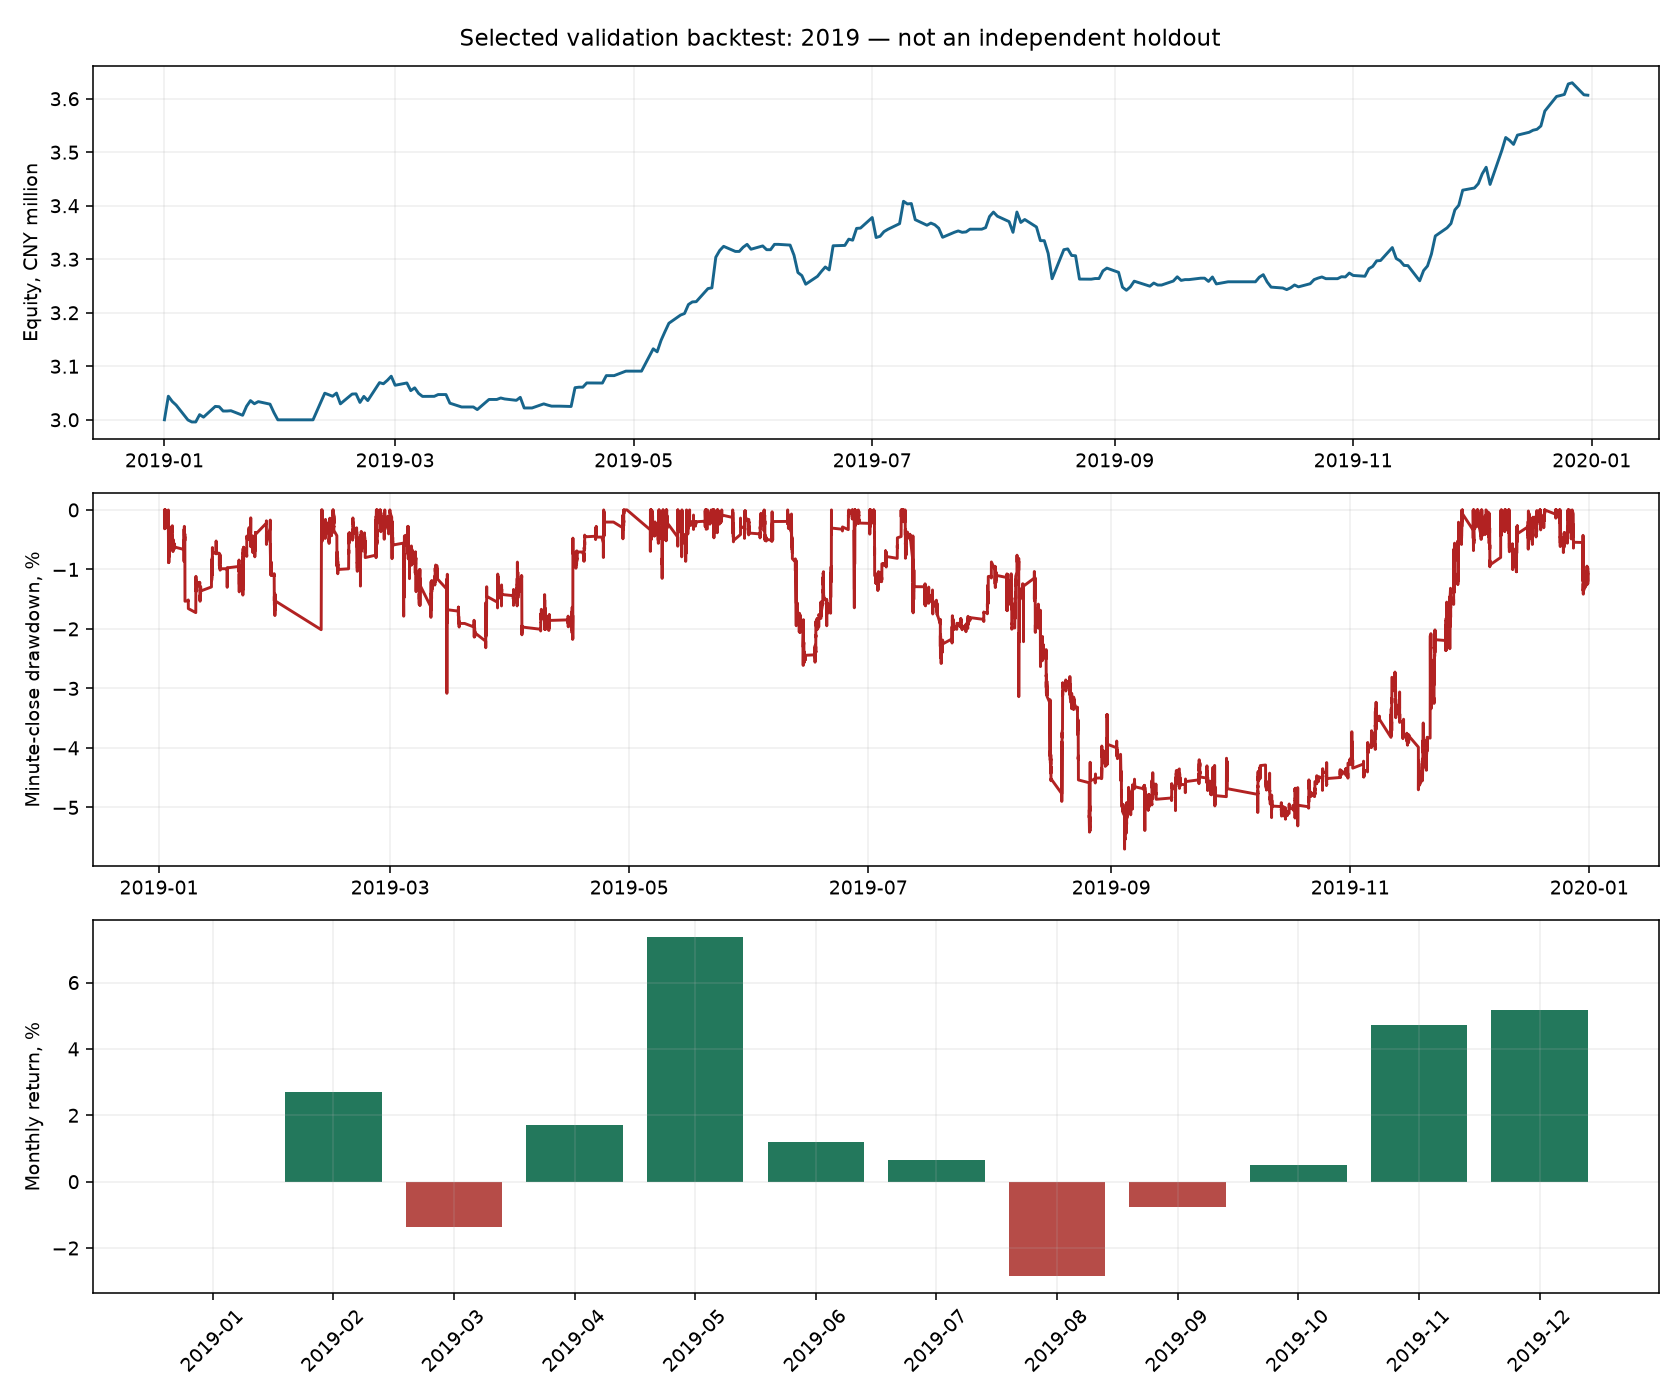

,date,equity_cny,return_pct
0,2019-01-31,2.999894e+06,-0.003521
1,2019-02-28,3.081403e+06,2.717040
2,2019-03-31,3.038907e+06,-1.379096
3,2019-04-30,3.090896e+06,1.710760
4,2019-05-31,3.318730e+06,7.371148
5,2019-06-30,3.358260e+06,1.191130
6,2019-07-31,3.379815e+06,0.641835
7,2019-08-31,3.283441e+06,-2.851457
8,2019-09-30,3.257883e+06,-0.778391
9,2019-10-31,3.274200e+06,0.500834


,ticks_per_side,annualized_return_pct,sharpe,max_drawdown_pct,all_required_pass
0,1,20.235032,2.509002,5.701398,True
1,2,6.412655,0.830112,9.022919,False
2,3,-8.015294,-1.006311,14.943952,False


In [4]:
display(Image(filename=str(out / 'performance.png')))
display(pd.read_csv(out / 'monthly.csv'))
display(pd.read_csv(out / 'cost_sensitivity.csv')[['ticks_per_side', 'annualized_return_pct', 'sharpe', 'max_drawdown_pct', 'all_required_pass']])

## 4. Отчёт и тесты

Selection bias от перебора и выбора на 2019 сохраняется. Mixed-symbol дни и неполные блоки имеют ex-post data-quality фильтры. Этот ноутбук демонстрирует годовой бэктест задания на выбранном периоде и не выдаёт его за независимую оценку.

In [5]:
import subprocess, sys
check = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-v'], capture_output=True, text=True)
print(check.stdout + check.stderr)
assert check.returncode == 0
display(FileLink(str(out / 'MFT_Assignment_Validation.pdf')))
display(FileLink(str(out / 'REPORT.md')))
display(FileLink(str(out / 'manifest.json')))

test_bps_and_both_slippage_sides (test_opening_move_final.BacktestTests.test_bps_and_both_slippage_sides) ... ok
test_first_loss_drawdown_includes_initial_capital (test_opening_move_final.BacktestTests.test_first_loss_drawdown_includes_initial_capital) ... ok
test_previous_close_retains_mixed_day_and_missing_open_rejected (test_opening_move_final.BacktestTests.test_previous_close_retains_mixed_day_and_missing_open_rejected) ... ok
test_simulation_reconciles_and_enforces_margin_without_minimum_one (test_opening_move_final.BacktestTests.test_simulation_reconciles_and_enforces_margin_without_minimum_one) ... ok
test_simultaneous_positions_share_margin_and_entry_cost_budget (test_opening_move_final.BacktestTests.test_simultaneous_positions_share_margin_and_entry_cost_budget) ... ok
test_training_threshold_ignores_future (test_opening_move_final.BacktestTests.test_training_threshold_ignores_future) ... ok
test_fee_units (test_portfolio_engine.PortfolioTests.test_fee_units) ... ok
test_liqui

/home/egorzobkov/cmf/MFT_HW/reports/assignment_validation/MFT_Assignment_Validation.pdf

/home/egorzobkov/cmf/MFT_HW/reports/assignment_validation/REPORT.md

/home/egorzobkov/cmf/MFT_HW/reports/assignment_validation/manifest.json